# Soil Properties Data Gridding and Crop Filtering # 
This notebook works to: 
- combine soil property data into one df
- gridding and crop filtering the soil prop data to same specs as the rest of data 

In [1]:
import rioxarray 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [2]:
import sys
print(sys.executable)

/global/home/users/rubypercival/.conda/envs/atmos_env/bin/python


# Merge soil props to one dataset

In [3]:
datasets = {
    "clay_percent":"/global/scratch/users/rubypercival/Soil_properties_data/clay_05.tif",
    "sand_percent":"/global/scratch/users/rubypercival/Soil_properties_data/sand_05.tif",
    "silt_percent":"/global/scratch/users/rubypercival/Soil_properties_data/silt.tif",
    "ksat":"/global/scratch/users/rubypercival/Soil_properties_data/ksat_05.tif",
    "ph":"/global/scratch/users/rubypercival/Soil_properties_data/ph_05.tif",
    "soil_om_kg_m2":"/global/scratch/users/rubypercival/Soil_properties_data/om_kg_sq_m.tif",
    "soil_texture":"/global/scratch/users/rubypercival/Soil_properties_data/texture_05.tif",
    "bulk_density":"/global/scratch/users/rubypercival/Soil_properties_data/db.tif",
    "water_storage":"/global/scratch/users/rubypercival/Soil_properties_data/paws_025.tif"}


In [5]:
 def tif_to_df(filepath, col_name):
    da = rioxarray.open_rasterio(filepath, masked=True)
    da =da.rio.reproject("EPSG:4326")
    df = da[0].to_pandas()
    df["lat"] =df.index
    df =pd.melt(df, id_vars="lat", var_name="lon", value_name=col_name)
    return df

In [6]:
df_merged =None

for col_name, filepath in datasets.items():
    print(f"processing {col_name}")
    df = tif_to_df(filepath, col_name)

    if df_merged is None:
        df_merged = df
    else:
        #merge on lat/long
        df_merged = df_merged.merge(df[["lat", "lon", col_name]],on=["lat", "lon"], how="outer")

print("done, the shape is:", df_merged.shape)
print(df_merged.head())

processing clay_percent
processing sand_percent
processing silt_percent
processing ksat
processing ph
processing soil_om_kg_m2
processing soil_texture
processing bulk_density
processing water_storage
done, the shape is: (47577620, 11)
         lat         lon  clay_percent  sand_percent  silt_percent  ksat  ph  \
0  22.868869 -127.892563           NaN           NaN           NaN   NaN NaN   
1  22.868869 -127.883877           NaN           NaN           NaN   NaN NaN   
2  22.868869 -127.875191           NaN           NaN           NaN   NaN NaN   
3  22.868869 -127.866505           NaN           NaN           NaN   NaN NaN   
4  22.868869 -127.857819           NaN           NaN           NaN   NaN NaN   

   soil_om_kg_m2  soil_texture  bulk_density  water_storage  
0            NaN           NaN           NaN            NaN  
1            NaN           NaN           NaN            NaN  
2            NaN           NaN           NaN            NaN  
3            NaN           NaN      

In [6]:
df_merged

,lat,lon,clay_percent,sand_percent,silt_percent,ksat,ph,soil_om_kg_m2,soil_texture,bulk_density,water_storage
0,22.868869,-127.892563,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,22.868869,-127.883877,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,22.868869,-127.875191,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,22.868869,-127.866505,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,22.868869,-127.857819,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
47577615,51.602428,-65.379915,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
47577616,51.602428,-65.371224,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
47577617,51.602428,-65.362533,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
47577618,51.602428,-65.353842,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df_merged['soil_texture'].unique()

array([nan,  1.,  5.,  2.,  4.,  3.,  9.,  8., 11., 12.,  7., 10.,  6.],
      dtype=float32)

# Regridding

In [8]:
df_filtered = df_merged[
    (pd.to_numeric(df_merged["lon"], errors="coerce") >= -104) &
    (pd.to_numeric(df_merged["lon"], errors="coerce") <= -80) &
    (pd.to_numeric(df_merged["lat"], errors="coerce") >= 36) &
    (pd.to_numeric(df_merged["lat"], errors="coerce") <= 49)].copy()

df_filtered["lat"] =pd.to_numeric(df_filtered["lat"], errors="coerce")
df_filtered["lon"] =pd.to_numeric(df_filtered["lon"], errors="coerce")

#bin to a 0.1 degree grid
res =0.1
df_filtered["lat_bin"] = (np.floor(df_filtered["lat"] /res) * res +res / 2).round(2)
df_filtered["lon_bin"] = (np.floor(df_filtered["lon"] /res) * res +res / 2).round(2)

texture_map = {
    1: "sand",
    2: "loamy sand",
    3: "sandy loam",
    4: "loam",
    5: "silt loam",
    6: "silt",
    7: "sandy clay loam",
    8: "clay loam",
    9: "silty clay loam",
    10: "sandy clay",
    11: "silty clay",
    12: "clay"}

df_filtered["texture_class"] = df_filtered["soil_texture"].map(texture_map)

In [9]:
continuous_cols = ["clay_percent", "sand_percent", "silt_percent", "ksat","ph", "soil_om_kg_m2", "bulk_density", "water_storage"]

df_cont = (df_filtered.groupby(["lat_bin", "lon_bin"])[continuous_cols].mean().reset_index())

In [10]:
def mode_or_nan(x):
    x = x.dropna()
    if len(x) == 0:
        return np.nan
    return x.mode().iloc[0]
    
texture_col = "texture_class"
df_texture = (df_filtered.groupby(["lat_bin", "lon_bin"])[texture_col].apply(mode_or_nan)
              .reset_index().rename(columns={texture_col: "dominant_texture"}))

texture_counts = (df_filtered.dropna(subset=[texture_col]).groupby(["lat_bin", "lon_bin", texture_col])
                  .size().reset_index(name="n_pixels"))

texture_counts["total_pixels"] =(texture_counts.groupby(["lat_bin", "lon_bin"])["n_pixels"].transform("sum"))

texture_counts["pct"] =texture_counts["n_pixels"] /texture_counts["total_pixels"] *100

texture_pct = (texture_counts.pivot(index=["lat_bin", "lon_bin"], columns=texture_col, values="pct").fillna(0).reset_index())
texture_pct.columns.name = None
texture_pct = texture_pct.rename(columns={c: f"pct_{str(c).lower().replace(' ', '_').replace('/', '_')}"
                                          for c in texture_pct.columns
                                          if c not in ["lat_bin", "lon_bin"]})


df_regridded = (df_cont
                .merge(df_texture, on=["lat_bin", "lon_bin"], how="outer")
                .merge(texture_pct, on=["lat_bin", "lon_bin"], how="left"))

df_regridded = df_regridded.rename(columns={"lat_bin": "lat", "lon_bin": "lon"})

print(df_regridded.head())
print(df_regridded.shape)

     lat     lon  clay_percent  sand_percent  silt_percent       ksat  \
0  36.05 -103.95     18.860806     50.316406     33.525398  18.546001   
1  36.05 -103.85     20.988934     45.646191     34.711666  12.125627   
2  36.05 -103.75     17.977577     51.328522     33.702927  11.456882   
3  36.05 -103.65     18.394190     51.840191     32.335793  11.282749   
4  36.05 -103.55     18.651203     52.877113     33.274269  14.623668   

         ph  soil_om_kg_m2  bulk_density  water_storage  ...   pct_loam  \
0  7.789081       7.367628      1.448349       3.762503  ...  65.972222   
1  7.623794       7.353674      1.458530       4.010623  ...  79.545455   
2  7.745351       5.556067      1.470257       3.494721  ...  56.944444   
3  7.587721       5.786938      1.485116       3.536863  ...  46.212121   
4  7.618638       7.991059      1.504199       3.715473  ...  45.138889   

   pct_loamy_sand  pct_sand  pct_sandy_clay  pct_sandy_clay_loam  \
0             0.0       0.0             0.

In [11]:
df_regridded.columns

Index(['lat', 'lon', 'clay_percent', 'sand_percent', 'silt_percent', 'ksat',
       'ph', 'soil_om_kg_m2', 'bulk_density', 'water_storage',
       'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam'],
      dtype='str')

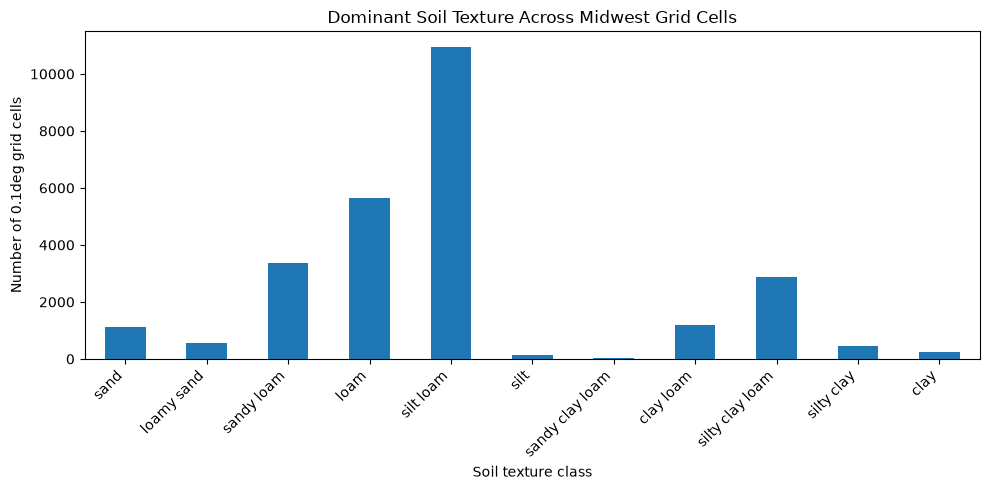

In [12]:
plot_df = df_regridded.dropna(subset=["dominant_texture"]).copy()

texture_order = [
    "sand", "loamy sand", "sandy loam", "loam",
    "silt loam", "silt", "sandy clay loam", "clay loam",
    "silty clay loam", "sandy clay", "silty clay", "clay"]

texture_counts = (plot_df["dominant_texture"].value_counts().reindex(texture_order).dropna())

plt.figure(figsize=(10, 5))
texture_counts.plot(kind="bar")
plt.ylabel("Number of 0.1deg grid cells")
plt.xlabel("Soil texture class")
plt.title("Dominant Soil Texture Across Midwest Grid Cells")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

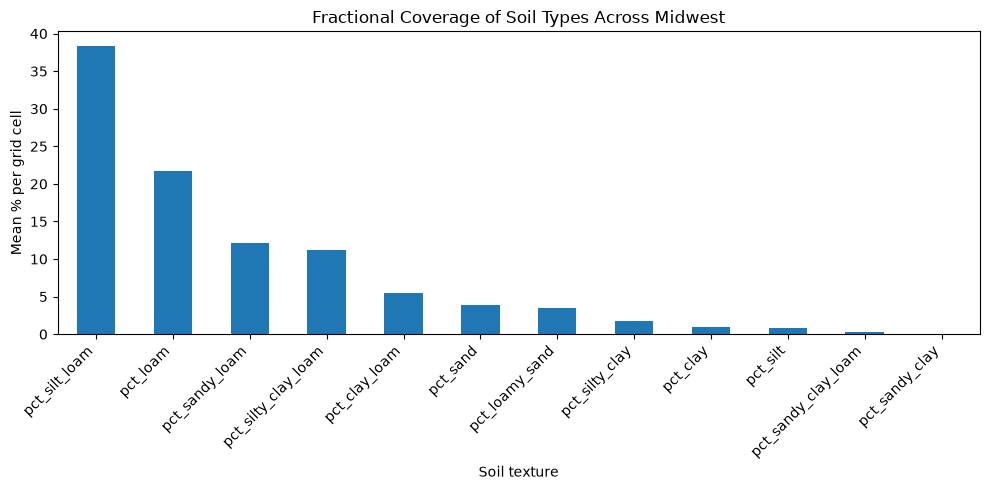

In [13]:
pct_cols = [c for c in df_regridded.columns if c.startswith("pct_")]

texture_fraction = df_regridded[pct_cols].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
texture_fraction.plot(kind="bar")
plt.ylabel("Mean % per grid cell")
plt.xlabel("Soil texture")
plt.title("Fractional Coverage of Soil Types Across Midwest")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

/tmp/ipykernel_3709674/230730634.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
/tmp/ipykernel_3709674/230730634.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(#handles=handles,


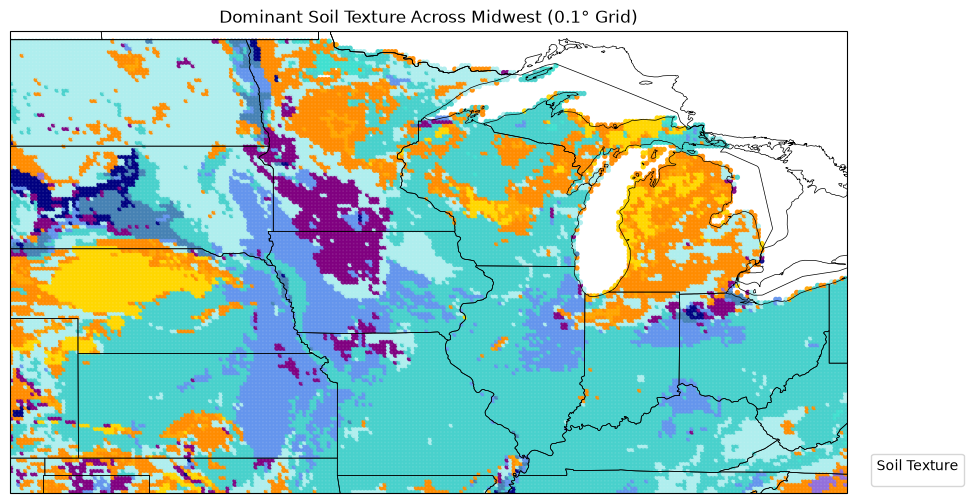

In [14]:
# assign each texture a color
texture_colors = {
    "sand": "gold",
    "loamy sand": "orange",
    "sandy loam": "darkorange",
    "loam": "paleturquoise",
    "silt loam": "mediumturquoise",
    "silt": "turquoise",
    "sandy clay loam": "mediumpurple",
    "clay loam": "purple",
    "silty clay loam": "cornflowerblue",
    "sandy clay": "red",
    "silty clay": "steelblue",
    "clay": "navy"}

map_df = df_regridded.dropna(subset=["dominant_texture"]).copy()
map_df["color"] = map_df["dominant_texture"].map(texture_colors)

fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.scatter( map_df["lon"], map_df["lat"],c=map_df["color"], s=8, alpha=0.9, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.STATES, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.legend()
ax.set_extent([-104, -80, 36, 49])
ax.legend(#handles=handles,
    title="Soil Texture", loc="lower left", bbox_to_anchor=(1.02, 0), ncol=2)

plt.title("Dominant Soil Texture Across Midwest (0.1° Grid)")
plt.show()

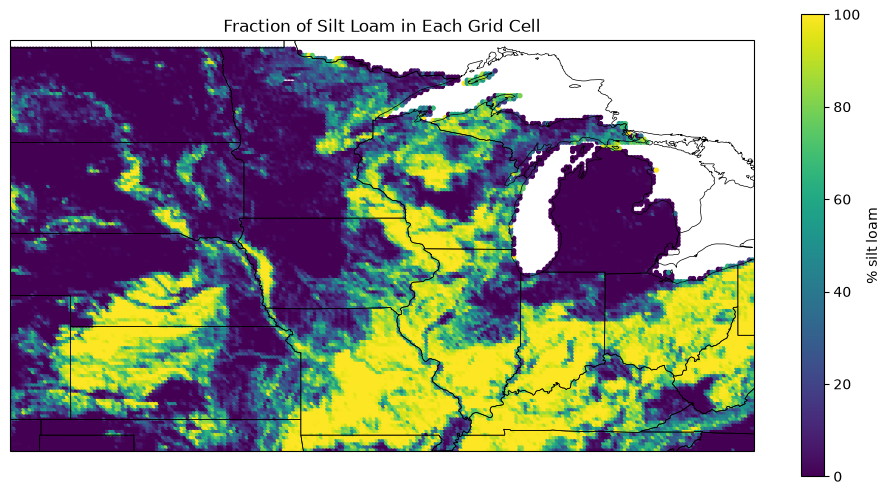

In [15]:
fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.PlateCarree())

sc = ax.scatter(df_regridded["lon"], df_regridded["lat"], c=df_regridded["pct_silt_loam"], s=8, cmap="viridis",
                transform=ccrs.PlateCarree())

ax.add_feature(cfeature.STATES, linewidth=0.5)
ax.set_extent([-104, -80, 36, 49])

plt.colorbar(sc, label="% silt loam")
plt.title("Fraction of Silt Loam in Each Grid Cell")
plt.show()

# crop filter soil prop data

In [16]:
crop_mask = '/global/scratch/users/rubypercival/MODIS24/0.1x0.1_cropland_mask_MCD12Q1'
crop_df= pd.read_parquet(crop_mask, engine='pyarrow')


In [17]:
crop_df

,grid_lat,grid_lon,is_majority_cropland
11,36.05,-102.85,True
12,36.05,-102.75,True
13,36.05,-102.65,True
14,36.05,-102.55,True
15,36.05,-102.45,True
...,...,...,...
31028,48.95,-97.15,True
31029,48.95,-97.05,True
31030,48.95,-96.95,True
31031,48.95,-96.85,True


In [18]:
crop_filtered = (crop_df.loc[crop_df["is_majority_cropland"] == True, ["grid_lat", "grid_lon"]]
                 .rename(columns={"grid_lat": "lat", "grid_lon": "lon"}).copy())
crop_filtered["lat"] = crop_filtered["lat"].astype('float64').round(2)
crop_filtered["lon"] = crop_filtered["lon"].astype('float64').round(2)

df_regridded["lat"] = df_regridded["lat"].astype('float64').round(2)
df_regridded["lon"] = df_regridded["lon"].astype('float64').round(2)

df_soil_cropland = df_regridded.merge(crop_filtered.drop_duplicates(), on=["lat", "lon"], how="inner")

print("final shape:", df_soil_cropland.shape)
print("Soil props merged cells:", df_soil_cropland[["lat","lon"]].drop_duplicates().shape[0])
print(df_soil_cropland.head())


final shape: (10995, 23)
Soil props merged cells: 10995
     lat     lon  clay_percent  sand_percent  silt_percent       ksat  \
0  36.05 -102.85     11.638680     74.002556     18.607601  61.732197   
1  36.05 -102.75     12.775354     71.485878     21.009079  56.240265   
2  36.05 -102.65     17.036133     60.306217     24.407776  35.680111   
3  36.05 -102.55     16.809649     60.124825     23.102362  26.228291   
4  36.05 -102.45     20.905479     50.238453     28.418425  17.662106   

         ph  soil_om_kg_m2  bulk_density  water_storage  ...   pct_loam  \
0  7.360669      11.580418      1.551855       3.029991  ...   3.030303   
1  7.344618      12.174961      1.538737       3.161655  ...   9.722222   
2  7.506711      12.591521      1.529121       3.555697  ...  27.272727   
3  7.525783      11.951220      1.531920       3.554892  ...  20.138889   
4  7.445413      13.124508      1.512756       3.975861  ...  48.484848   

   pct_loamy_sand  pct_sand  pct_sandy_clay  pct_sandy

In [19]:
df_soil_cropland

,lat,lon,clay_percent,sand_percent,silt_percent,ksat,ph,soil_om_kg_m2,bulk_density,water_storage,...,pct_loam,pct_loamy_sand,pct_sand,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam
0,36.05,-102.85,11.638680,74.002556,18.607601,61.732197,7.360669,11.580418,1.551855,3.029991,...,3.030303,31.818182,1.515152,0.0,0.757576,62.878788,0.000000,0.00,0.000000,0.000000
1,36.05,-102.75,12.775354,71.485878,21.009079,56.240265,7.344618,12.174961,1.538737,3.161655,...,9.722222,27.777778,0.000000,0.0,1.388889,59.722222,0.000000,0.00,0.000000,0.000000
2,36.05,-102.65,17.036133,60.306217,24.407776,35.680111,7.506711,12.591521,1.529121,3.555697,...,27.272727,11.363636,0.000000,0.0,6.060606,52.272727,0.000000,0.00,0.000000,0.000000
3,36.05,-102.55,16.809649,60.124825,23.102362,26.228291,7.525783,11.951220,1.531920,3.554892,...,20.138889,0.694444,0.000000,0.0,6.250000,72.222222,0.000000,0.00,0.000000,0.000000
4,36.05,-102.45,20.905479,50.238453,28.418425,17.662106,7.445413,13.124508,1.512756,3.975861,...,48.484848,0.000000,0.000000,0.0,2.272727,37.878788,0.000000,0.00,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10990,48.95,-97.15,38.919182,7.280471,56.245403,5.720787,7.532484,40.113480,1.365370,4.589786,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.00,36.111111,59.027778
10991,48.95,-97.05,64.871246,8.780170,24.858475,0.833220,7.557151,49.562973,1.218033,3.597396,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.00,12.878788,0.757576
10992,48.95,-96.95,43.938663,30.357338,24.991348,11.973577,7.467688,41.732445,1.420882,3.998168,...,14.583333,0.000000,0.000000,0.0,0.000000,25.000000,0.000000,0.00,0.000000,0.000000
10993,48.95,-96.85,11.336518,68.038681,20.021000,48.102066,7.383735,24.475515,1.640658,3.783444,...,4.545455,5.303030,0.000000,0.0,1.515152,88.636364,0.000000,0.00,0.000000,0.000000


In [20]:
df_soil_cropland['dominant_texture'].unique()

<ArrowStringArray>
[     'sandy loam',            'loam',       'clay loam', 'silty clay loam',
       'silt loam',      'loamy sand',            'clay',      'silty clay',
            'sand', 'sandy clay loam',               nan]
Length: 11, dtype: str

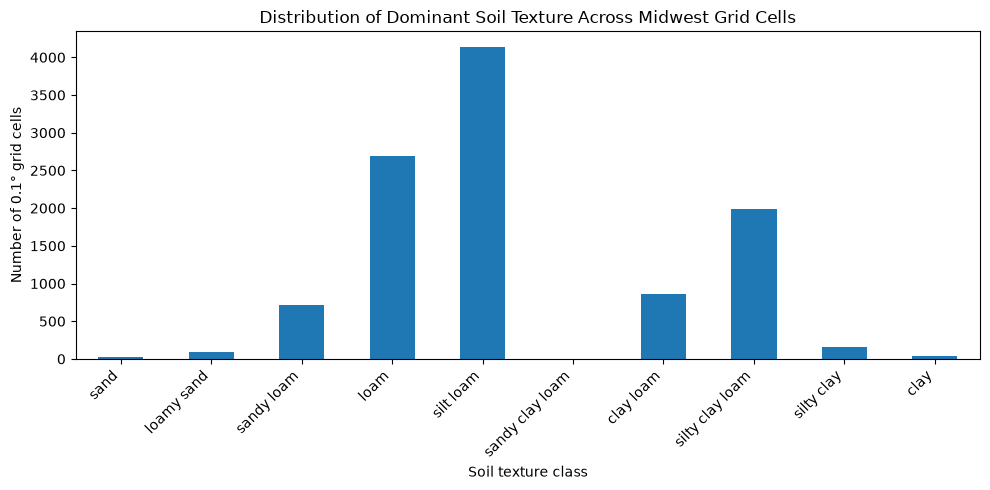

In [21]:
plot_df = df_soil_cropland.dropna(subset=["dominant_texture"]).copy()

texture_counts = (plot_df["dominant_texture"].value_counts().reindex(texture_order).dropna())

plt.figure(figsize=(10, 5))
texture_counts.plot(kind="bar")
plt.ylabel("Number of 0.1° grid cells")
plt.xlabel("Soil texture class")
plt.title("Distribution of Dominant Soil Texture Across Midwest Grid Cells")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

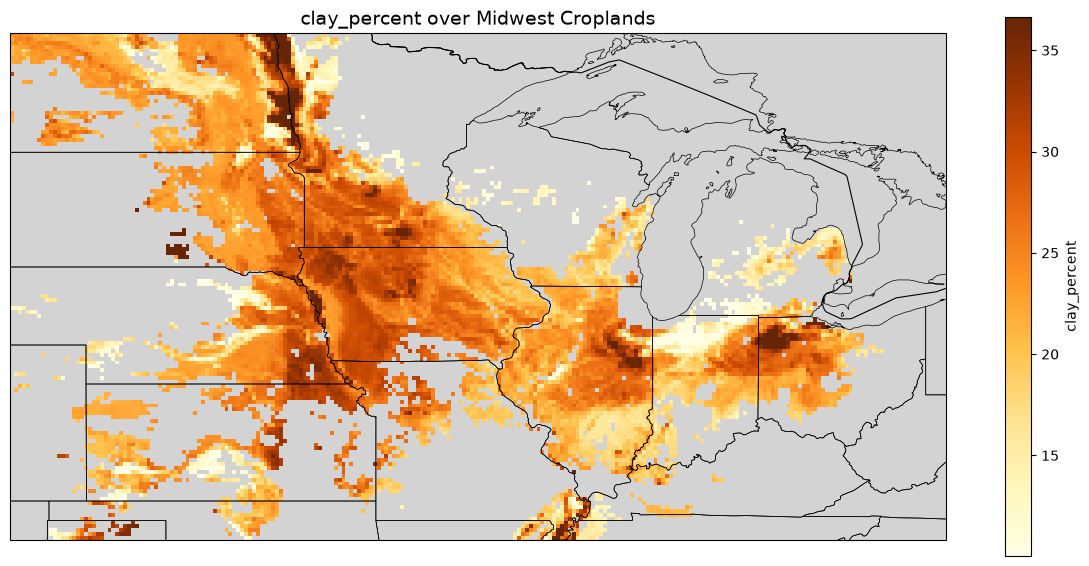

In [22]:
fig, ax = plt.subplots(figsize=(12, 8),subplot_kw={"projection": ccrs.PlateCarree()})

ax.set_extent([-104, -80, 36, 49],crs=ccrs.PlateCarree())
ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor="black")
ax.add_feature(cfeature.BORDERS, linewidth=0.8, edgecolor="black")
ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.add_feature(cfeature.OCEAN, facecolor="lightblue")

soil_var = "clay_percent"
res = 0.1

#pivot to 2D grid
grid = df_soil_cropland.pivot(index="lat", columns="lon", values=soil_var)
lats =grid.index.values
lons =grid.columns.values
data =grid.values

# create cell edges (centers +/- half res)
lat_edges = np.concatenate([lats - res/2, [lats[-1] + res/2]])
lon_edges = np.concatenate([lons - res/2, [lons[-1] + res/2]])

mesh = ax.pcolormesh(lon_edges, lat_edges, data, cmap="YlOrBr", transform=ccrs.PlateCarree(),
                     vmin=np.nanquantile(data, 0.02), vmax=np.nanquantile(data, 0.98))

plt.colorbar(mesh, ax=ax, label=soil_var, shrink=0.7)
ax.set_title(f"{soil_var} over Midwest Croplands", fontsize=14)

plt.tight_layout()
plt.show()

In [23]:
df_soil_cropland.columns

Index(['lat', 'lon', 'clay_percent', 'sand_percent', 'silt_percent', 'ksat',
       'ph', 'soil_om_kg_m2', 'bulk_density', 'water_storage',
       'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam'],
      dtype='str')

In [24]:
from pathlib import Path
output_file= '/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/soil_props_GCF_MCD12Q1mask_24.parquet'
Path(output_file).parent.mkdir(parents=True, exist_ok=True)
df_soil_cropland.to_parquet(output_file, index=False)


In [25]:
df_soil_cropland

,lat,lon,clay_percent,sand_percent,silt_percent,ksat,ph,soil_om_kg_m2,bulk_density,water_storage,...,pct_loam,pct_loamy_sand,pct_sand,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam
0,36.05,-102.85,11.638680,74.002556,18.607601,61.732197,7.360669,11.580418,1.551855,3.029991,...,3.030303,31.818182,1.515152,0.0,0.757576,62.878788,0.000000,0.00,0.000000,0.000000
1,36.05,-102.75,12.775354,71.485878,21.009079,56.240265,7.344618,12.174961,1.538737,3.161655,...,9.722222,27.777778,0.000000,0.0,1.388889,59.722222,0.000000,0.00,0.000000,0.000000
2,36.05,-102.65,17.036133,60.306217,24.407776,35.680111,7.506711,12.591521,1.529121,3.555697,...,27.272727,11.363636,0.000000,0.0,6.060606,52.272727,0.000000,0.00,0.000000,0.000000
3,36.05,-102.55,16.809649,60.124825,23.102362,26.228291,7.525783,11.951220,1.531920,3.554892,...,20.138889,0.694444,0.000000,0.0,6.250000,72.222222,0.000000,0.00,0.000000,0.000000
4,36.05,-102.45,20.905479,50.238453,28.418425,17.662106,7.445413,13.124508,1.512756,3.975861,...,48.484848,0.000000,0.000000,0.0,2.272727,37.878788,0.000000,0.00,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10990,48.95,-97.15,38.919182,7.280471,56.245403,5.720787,7.532484,40.113480,1.365370,4.589786,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.00,36.111111,59.027778
10991,48.95,-97.05,64.871246,8.780170,24.858475,0.833220,7.557151,49.562973,1.218033,3.597396,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.00,12.878788,0.757576
10992,48.95,-96.95,43.938663,30.357338,24.991348,11.973577,7.467688,41.732445,1.420882,3.998168,...,14.583333,0.000000,0.000000,0.0,0.000000,25.000000,0.000000,0.00,0.000000,0.000000
10993,48.95,-96.85,11.336518,68.038681,20.021000,48.102066,7.383735,24.475515,1.640658,3.783444,...,4.545455,5.303030,0.000000,0.0,1.515152,88.636364,0.000000,0.00,0.000000,0.000000
